# <u>Partie 4 : Data Engineering (question bonus)</u>

1. **Modèle de données** : schéma des tables sources (contrats, paiements Stripe, remboursements) et de leurs liens, puis modèle cible de l'entrepôt avec des tables de faits et des dimensions.

2. **Data warehouse** : les étapes pour le construire (collecte, nettoyage, transformation, tables finales), les transformations à faire et les outils choisis.

3. **Prototype** : la couche finale (« gold ») écrite en SQL à partir des tables nettoyées, avec des tests de qualité et une vérification que ses chiffres correspondent à ceux de la partie 2.

### Chargement des packages requis 

In [33]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

### Modules du projet 

In [34]:
sys.path.insert(0, str(Path.cwd().parent))
from src.config import DATE_EXTRACTION, DOSSIER_PROPRE, RACINE
from src.diagrammes import H_LIGNE, boite_etape, boite_table, fleche, relier
from src.style import ENCRE, STATUT, appliquer_style, nb, sauver

### Réglages d'affichage

In [35]:
appliquer_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

## <u>1. Modèle de données</u>

###  Modèle source : relations entre les tables

Le fichier excel contient 4 tables, mais deux entités n'ont pas de table propre : le **client** (`user_id`, répété dans les contrats) et les **bénéficiaires** (stockés en liste JSON dans `list_beneficiaries_id`, à déplier pour relier chaque remboursement à la bonne personne).

**J'ai obtenu le diagramme en exécutant le code suivant sur Mermaid :** 

flowchart LR
    CLIENT["<b>CLIENT</b> (implicite)<br/>user_id"]
    PRODUITS["<b>PRODUITS</b><br/>id"]
    CONTRATS["<b>CONTRATS</b><br/>contrat_id<br/>user_id, product_id<br/>list_beneficiaries_id"]
    STRIPE["<b>STRIPE</b><br/>contract_id<br/>amount, status"]
    REMBOURSEMENTS["<b>REMBOURSEMENTS</b><br/>contract_id, beneficiary_id<br/>amount_refund_mutual"]
    BENEFICIAIRES["<b>BENEFICIAIRES</b> (dérivée)<br/>contract_id, beneficiary_id"]

    CLIENT -->|"1,N<br/>user_id"| CONTRATS
    PRODUITS -->|"1,N<br/>product_id"| CONTRATS
    CONTRATS -->|"0,N<br/>contract_id"| STRIPE
    CONTRATS -->|"0,N<br/>contract_id"| REMBOURSEMENTS
    CONTRATS -->|"1,N<br/>list_beneficiaries_id"| BENEFICIAIRES
    BENEFICIAIRES -->|"0,N<br/>beneficiary_id"| REMBOURSEMENTS

    style CLIENT stroke-dasharray: 5 5
    style BENEFICIAIRES stroke-dasharray: 5 5

### Affichage du diagramme

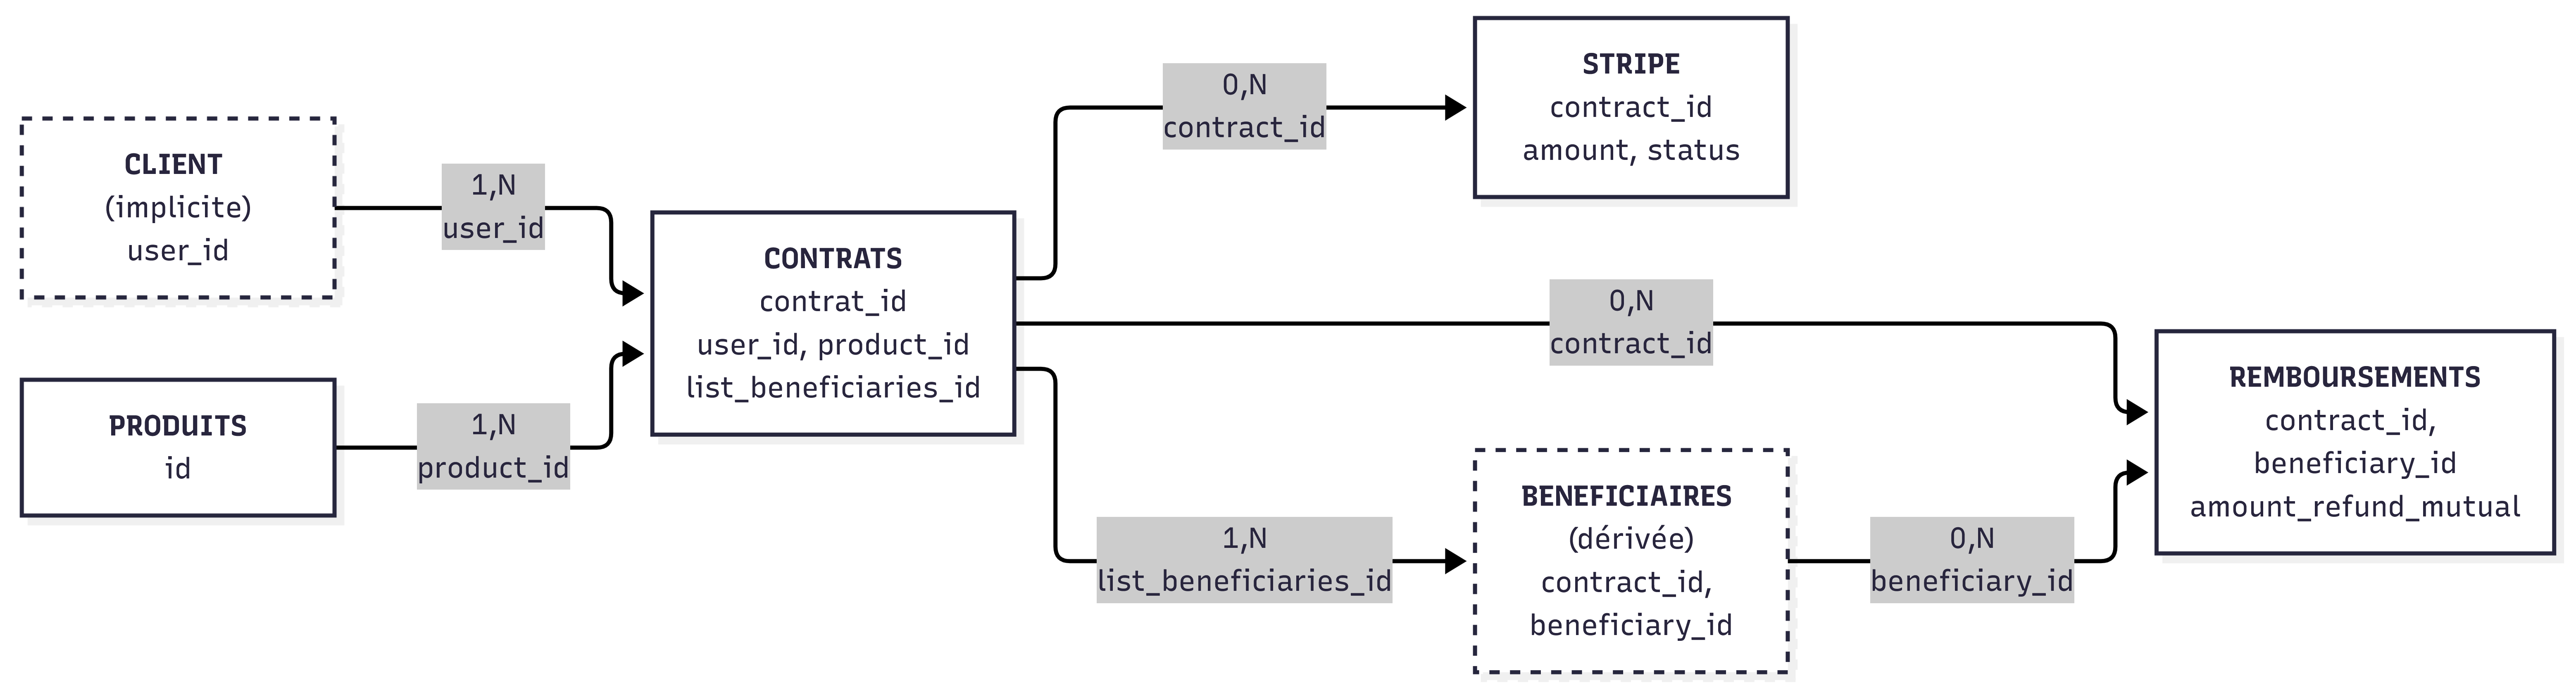

In [36]:
from IPython.display import display, Image

display(Image(filename="../figures/Relation_tables.png"))

### Lecture du diagramme

| Relation | Clé de jointure | Cardinalité |
|---|---|---|
| Produits → Contrats | `product_id` | 1 produit, N contrats |
| Client → Contrats | `user_id` | 1 client, N contrats (environ 170 clients en ont plusieurs) |
| Contrats → Stripe | `Contrat_id` = `Contract_id` | 1 contrat, 0 à N paiements |
| Contrats → Remboursements | `contract_id` | 1 contrat, 0 à N demandes ; une demande a 0 ou 1 contrat |
| Contrats → Bénéficiaires | liste `list_beneficiaries_id` | 1 contrat, 1 à N bénéficiaires ; un bénéficiaire peut avoir plusieurs contrats |
| Bénéficiaires → Remboursements | `beneficiary_id` | 1 bénéficiaire, 0 à N demandes |
| Produits → Stripe | `product_id` | redondant avec le contrat |

### Modèle cible de l'entrepôt

Le modèle cible est dimensionnel (Kimball) : des tables de **faits** enregistrent les événements mesurables (contrats, paiements, remboursements), et des tables de **dimensions** donnent le contexte d'analyse (client, produit, date).

**J'ai obtenu le diagramme du modèle entrepot en exécutant le code suivant sur Mermaid :**

flowchart LR
    subgraph FAITS["Tables de faits"]
        F1["<b>fct_paiement</b><br/>grain : 1 tentative Stripe<br/>montant, statut, motif_refus"]
        F2["<b>fct_contrat_mensuel</b><br/>grain : 1 contrat x 1 mois<br/>est_actif, est_perdu, cotisation_due,<br/>cotisation_encaissee, est_impaye"]
        F3["<b>fct_remboursement</b><br/>grain : 1 demande<br/>montant_demande, montant_ss,<br/>montant_rembourse, est_approuve"]
    end

    subgraph DIMS["Dimensions partagées"]
        D1["<b>dim_date</b><br/>date_key"]
        D2["<b>dim_client</b> (SCD2)<br/>client_key, segment"]
        D3["<b>dim_contrat</b> (SCD2)<br/>contrat_key"]
        D4["<b>dim_produit</b><br/>produit_key, niveau_garantie"]
        D5["<b>dim_beneficiaire</b><br/>beneficiaire_key"]
    end

    F1 -->|"N,1"| D1
    F1 -->|"N,1"| D2
    F1 -->|"N,1"| D3
    F1 -->|"N,1"| D4

    F2 -->|"N,1"| D1
    F2 -->|"N,1"| D2
    F2 -->|"N,1"| D3
    F2 -->|"N,1"| D4

    F3 -->|"N,1<br/>date demande et décision"| D1
    F3 -->|"N,1"| D2
    F3 -->|"N,1"| D3
    F3 -->|"N,1"| D4
    F3 -->|"N,1"| D5

    D3 <-->|"N,N<br/>bridge_contrat_beneficiaire"| D5

    classDef fait fill:#2a78d6,stroke:#1a4f94,color:#fff
    classDef dim fill:#cde2fb,stroke:#6a9fd8,color:#000
    class F1,F2,F3 fait
    class D1,D2,D3,D4,D5 dim

### Affichage du modèle de l'entrepot

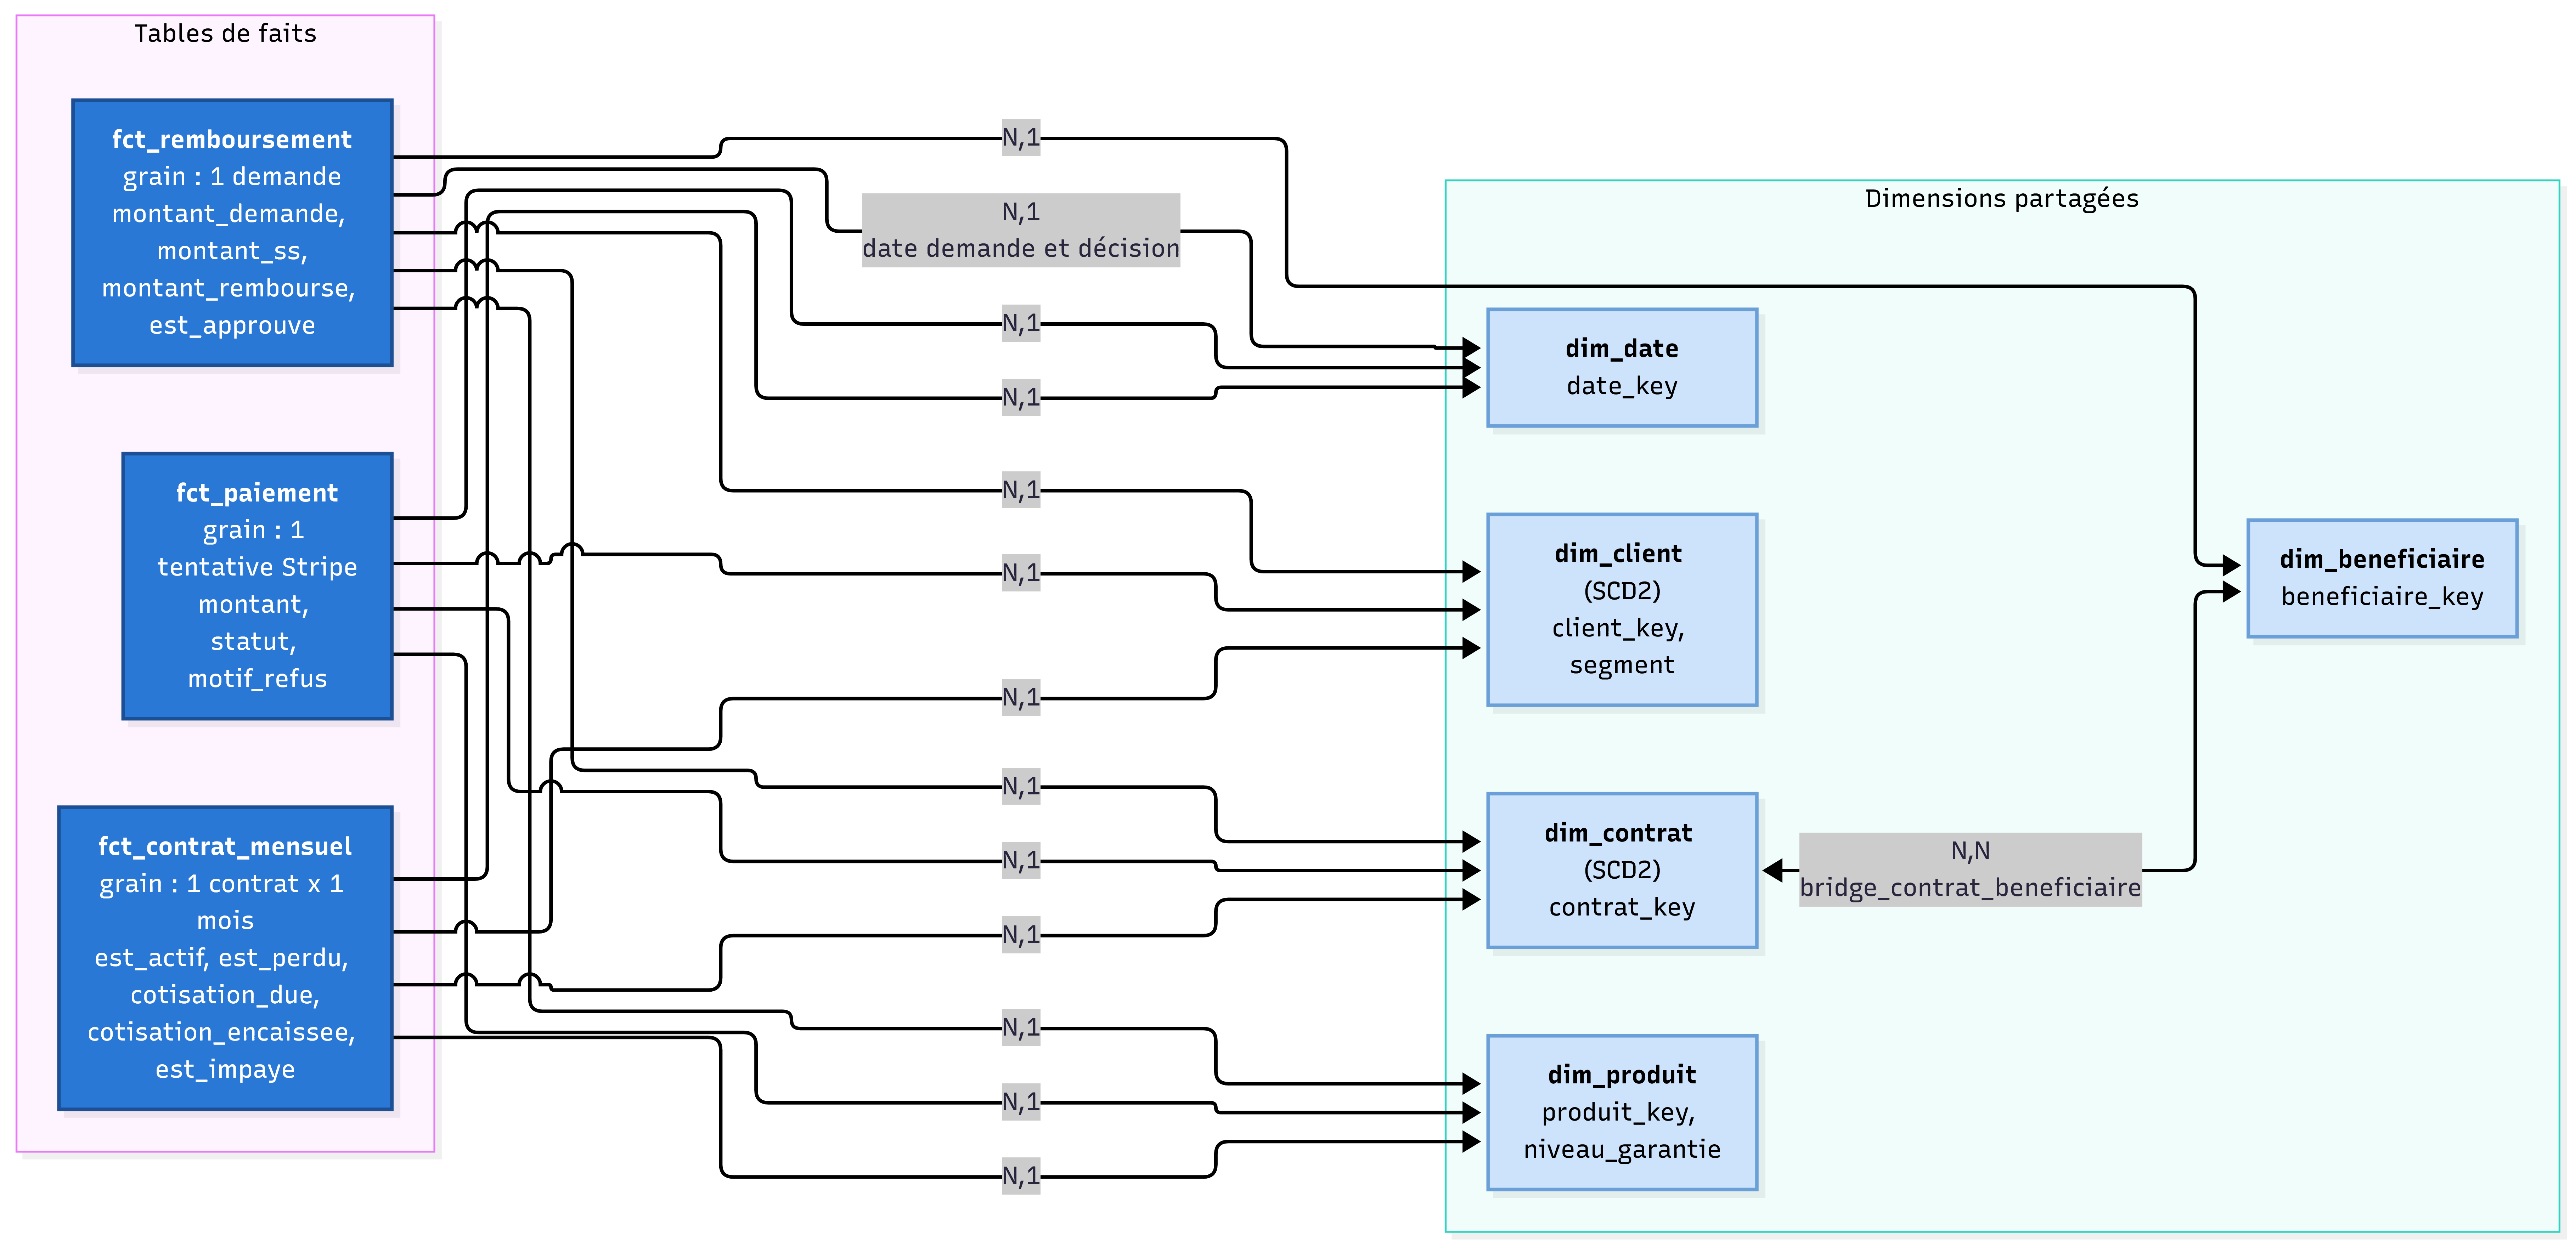

In [37]:
display(Image(filename="../figures/modele_entrepot.png"))

**Choix de modélisation**

- **Un grain explicite par fait** : une tentative de paiement (`fct_paiement`), une demande de remboursement (`fct_remboursement`), un contrat par mois (`fct_contrat_mensuel`).
- **`fct_contrat_mensuel` est une photo mensuelle** : une ligne par contrat et par mois, avec la cotisation due et encaissée, l'impayé et le statut actif ou perdu. Les indicateurs de la partie 2 (clients actifs, gagnés, perdus, taux d'impayé) deviennent de simples sommes.
- **Dimensions partagées** : les trois faits pointent vers les mêmes dimensions (date, client, contrat, produit). Seul `fct_remboursement` est relié à `dim_beneficiaire`, et il porte deux dates (demande et décision).
- **Historique (SCD2) sur `dim_client` et `dim_contrat`** : chaque changement crée une nouvelle version, ce qui permet d'analyser un fait avec les attributs en vigueur à sa date.
- **Relation contrat-bénéficiaire** : une table de liaison (`bridge_contrat_beneficiaire`) gère la relation N,N.
- **Le segment de la partie 3** est un attribut de `dim_client`.

## <U>2. Construction du data warehouse : démarche, transformations, outils</U>

### Architecture cible du data warehouse

In [38]:
FONCE, CLAIR, TXT = "#2a78d6", "#cde2fb", ENCRE["principale"]
HAUT, LARG, PAS = 8.9, 3.1, 3.4

ETAPES = [
    ("1. Sources", ["Application : contrats, adhérents", "Stripe : paiements", "Gestion des remboursements",
                    "Référentiel produits"], "PostgreSQL, API Stripe, exports"),
    ("2. Ingestion", ["Extraction incrémentale", "CDC sur la base applicative", "Connecteur API Stripe",
                      "Chargement brut, sans transformation"], "Airbyte ou Fivetran, Debezium, Python"),
    ("3. Bronze (brut)", ["Copie fidèle et horodatée", "Parquet partitionné par date", "Historique complet, rejouable",
                          "Aucune donnée supprimée"], "Stockage objet certifié HDS"),
    ("4. Silver (propre)", ["Typage : dates, montants", "Dédoublonnage des contrats", "Normalisation des libellés",
                            "Dépliage des bénéficiaires", "Lignes corrompues en quarantaine", "Flags qualité"],
     "dbt (SQL) ; PySpark si le volume l'exige"),
    ("5. Gold (métier)", ["Modèle en étoile", "Clés techniques, historique SCD2", "Photo mensuelle des contrats",
                          "Indicateurs : clients, S/P, impayés"], "Entrepôt : BigQuery, Snowflake ou PostgreSQL"),
    ("6. Usages", ["Tableaux de bord pilotage", "Data science : segments, churn", "Retour des scores vers le CRM",
                   "Exports réglementaires"], "Metabase ou Power BI, Python"),
]
BANDES = [
    ("Orchestration et CI/CD", "Airflow : DAG quotidien (ingestion, dbt build, tests, rafraîchissement BI), reprises et alertes ; "
                               "Git + CI : dbt build sur chaque modification, environnements dev / prod"),
    ("Qualité des données", "Tests à chaque exécution : unicité, non-nullité, intégrité référentielle, valeurs acceptées, "
                            "fraîcheur, règles métier issues de la partie 1 (dbt tests, Great Expectations)"),
    ("Sécurité et gouvernance", "Données de santé : hébergement certifié HDS, RGPD (minimisation, pseudonymisation), "
                                "accès par rôle, catalogue et lignage (dbt docs), durées de conservation"),
]

### Architecture cible du data warehouse : de la source à l'usage

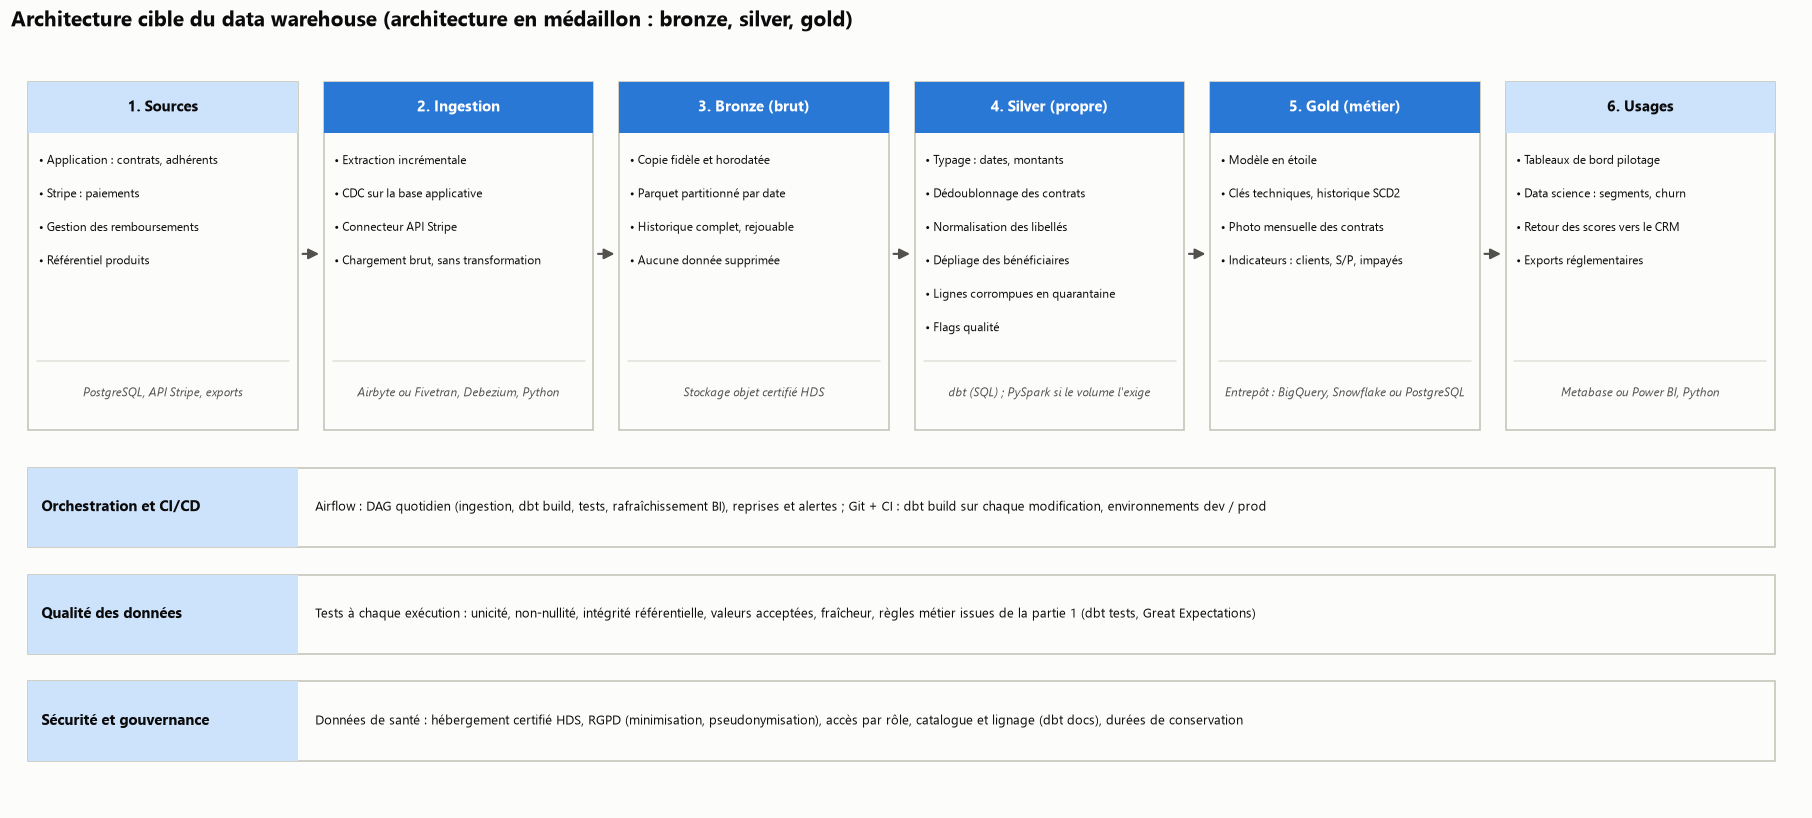

In [39]:
fig, ax = plt.subplots(figsize=(21, 9))
ax.set(xlim=(0, 20.6), ylim=(1.1, 9.3))
ax.axis("off")

# Étapes du pipeline, reliées par des flèches
boites = []
for i, (titre, lignes, outils) in enumerate(ETAPES):
    clair = i in (0, len(ETAPES) - 1)
    boites.append(boite_etape(ax, 0.2 + i * PAS, HAUT, LARG, 3.75, titre, lignes, outils=outils,
                              entete=CLAIR if clair else FONCE, texte_entete=TXT if clair else "white"))
for a, b in zip(boites, boites[1:]):
    fleche(ax, (a["x"] + a["w"] + 0.02, HAUT - 1.85), (b["x"] - 0.02, HAUT - 1.85))

# Bandes transversales
for j, (titre, texte) in enumerate(BANDES):
    y = 3.9 - j * 1.15
    ax.add_patch(Rectangle((0.2, y), 20.1, 0.85, facecolor=ENCRE["fond"], edgecolor=ENCRE["axe"], zorder=2))
    ax.add_patch(Rectangle((0.2, y), 3.1, 0.85, facecolor=CLAIR, edgecolor="none", zorder=3))
    ax.text(0.35, y + 0.425, titre, va="center", fontsize=9.5, fontweight="bold", color=TXT, zorder=4)
    ax.text(3.5, y + 0.425, texte, va="center", fontsize=8.6, color=TXT, zorder=4)

ax.set_title("Architecture cible du data warehouse (architecture en médaillon : bronze, silver, gold)", fontsize=14)
sauver(fig, "p4_architecture")
plt.show()

### Étape 1 : cadrage

- **Besoins** : définir avec le métier les indicateurs à piloter (clients actifs, gagnés et perdus, taux de perte, S/P, taux d'impayé, délai de remboursement, coût d'acquisition par canal) et leur définition exacte. La partie 2 a montré qu'une définition floue (« client perdu », « date de souscription ») change le résultat.
- **Sources et fréquence** : base applicative, Stripe, outil de remboursements, référentiel produits. Un rafraîchissement **quotidien** suffit.
- **Contraintes** : les remboursements sont des **données de santé** : hébergement certifié **HDS** et conformité RGPD (minimisation, pseudonymisation, accès restreints), à valider avec le DPO.
- **Volume** : environ 12 000 contrats, 170 000 paiements et 55 000 remboursements, soit moins d'un million de lignes. Un entrepôt SQL managé suffit ; Spark n'est pas nécessaire aujourd'hui.

### Étape 2 : ingestion

- **Base applicative** : extraction **incrémentale** (`updated_at`) ou capture des changements (**CDC**), qui aurait évité de perdre l'historique lors de la reprise du 03/06/2025.
- **Stripe** : connecteur API avec l'**identifiant de transaction** (absent du fichier fourni, X2), chargement incrémental avec quelques jours de recouvrement pour capter les changements de statut.
- **Remboursements** : export du système de gestion, idéalement par API, avec les dates de dépôt, de soin et de virement, qui manquent aujourd'hui (R10).
- **Fin des Excel et CSV manuels**, cause des dates en numéro de série, des virgules décimales et des lignes cassées (S1, S2, R2).
- **Outils** : Airbyte ou Fivetran, Debezium (CDC), Python.

### Étape 3 : couche bronze (données brutes)

- Copie **fidèle et horodatée** de chaque chargement, sans transformation, en Parquet partitionné par date.
- Elle permet de **rejouer** toute la chaîne et d'auditer une valeur jusqu'à sa source.
- **Outils** : stockage objet certifié HDS, ou schéma `raw` dans l'entrepôt.

### Étape 4 : couche silver (données propres)

L'industrialisation de la partie 1, en SQL versionné (un modèle dbt par table) :

- **Typage** : dates (numéros de série Excel, fuseau UTC vers Europe/Paris), montants, codes postaux en texte.
- **Dédoublonnage** : une ligne par `contract_id`, transactions en double supprimées.
- **Normalisation** : villes, statuts professionnels, canaux, motifs de refus.
- **Restructuration** : `list_beneficiaries_id` déplié en table pont.
- **Corrections sûres** : `Closed_Date` vidée pour les contrats en cours, statut Stripe prioritaire sur `Captured`.
- **Signalement** : calcul des `flag_*` (signature par défaut, paiement après clôture, paiement multiple).
- **Quarantaine** : les lignes inexploitables vont dans une table de rejets, au lieu d'être supprimées en silence.
- **Outils** : dbt ; PySpark seulement si le volume l'exige.

### Étape 5 : couche gold (modèle métier)

- Dimensions (avec membres inconnus), faits et photo mensuelle décrits en 1.2, avec **SCD2** (snapshots dbt) sur contrats et clients.
- Faits chargés en **incrémental**, dimensions reconstruites entièrement.
- Tables d'agrégats prêtes pour les tableaux de bord.
- **Outils** : dbt ; **PostgreSQL managé** à ce volume, **BigQuery** ou **Snowflake** pour absorber la croissance, dans une offre certifiée HDS.

### Étape 6 : qualité des données

Chaque anomalie de la partie 1 devient un **test automatique** à chaque chargement : un test bloquant arrête la chaîne avant les tableaux de bord, un avertissement alerte l'équipe sans bloquer.

| Anomalie | Règle | Test automatisé | Type |
|---|---|---|---|
| X1 | une ligne par contrat | `unique(contract_id)` | bloquant |
| X3, X7 | tout fait pointe vers un contrat connu | `relationships` vers `dim_contrat`, part de membres inconnus | avertissement au-delà d'un seuil |
| X4, X5 | un contrat actif a des paiements | contrats actifs sans paiement encaissé depuis 45 jours | avertissement |
| X11 | pas d'encaissement après clôture | paiements encaissés plus de 31 jours après la clôture | avertissement (finance) |
| X14 | pas de remboursement sans cotisation | remboursements approuvés sur contrat jamais encaissé | avertissement (gestion) |
| C1 | date de clôture cohérente avec le statut | `closed_date` vide si contrat en cours | bloquant |
| C5 | pas de date par défaut | aucune date de signature partagée par plus de 100 contrats | avertissement |
| S3 | statut et capture cohérents | échec ⇒ non capturé | bloquant |
| S7 | pas de double prélèvement | même contrat, même montant, même jour | avertissement (finance) |
| R2, R1 | lignes complètes | `not_null(created_at, is_approved)` | bloquant (ligne en quarantaine) |
| R6 | montant présent si approuvé | approuvé ⇒ montant renseigné | avertissement |
| tous | données à jour | dernier chargement de moins de 24 h | bloquant |

**Outils** : tests dbt (`unique`, `not_null`, `relationships`, `accepted_values`) et tests SQL personnalisés ; Great Expectations ou Soda pour les contrôles statistiques ; alertes Slack ou e-mail.

### Étape 7 : orchestration et CI/CD

- **DAG Airflow quotidien** (6 h) : extractions, chargement bronze, `dbt build` silver, snapshots SCD2, `dbt build` gold, contrôles métier, rafraîchissement des tableaux de bord, notification. Reprises automatiques, alertes et *backfill* possibles.
- Tâches **idempotentes** : relancer un jour ne crée pas de doublons.
- **Git et CI** : chaque modification est relue et testée par `dbt build` sur un environnement de test avant la production.
- **Outils** : Airflow (ou Dagster, Prefect), GitHub ou GitLab, Terraform.

### Étape 8 : exposition et usages

- **Tableaux de bord** sur la couche gold (acquisition, portefeuille et pertes, impayés, remboursements et S/P), avec des indicateurs définis une seule fois (couche sémantique dbt).
- **Data science** : variables par client pour la segmentation (partie 3) et un futur modèle de prédiction des départs, avec retour des scores vers le CRM (*reverse ETL*).
- **Outils** : Metabase ou Power BI ; Python.

### Étape 9 : sécurité et gouvernance

- **Pseudonymisation** des identifiants, données nominatives isolées dans une zone restreinte.
- **Accès par rôle** : le marketing voit les segments et indicateurs, pas le détail des remboursements de santé.
- **Catalogue et lignage** (dbt docs, DataHub) : chaque indicateur est documenté et traçable jusqu'à sa source.
- **Durées de conservation** conformes au RGPD, avec purge automatique.

### Récapitulatif des outils par étape

| Étape | Outils recommandés | Alternatives |
|---|---|---|
| Ingestion | Airbyte, Debezium (CDC), Python | Fivetran, Stitch |
| Stockage brut | stockage objet certifié HDS, Parquet | schéma `raw` dans l'entrepôt |
| Transformation | dbt (SQL) | PySpark si fort volume |
| Entrepôt | PostgreSQL managé | BigQuery, Snowflake |
| Qualité | tests dbt, Great Expectations | Soda |
| Orchestration | Airflow | Dagster, Prefect |
| Restitution | Metabase | Power BI, Looker Studio |
| Gouvernance | dbt docs, gestion des accès de l'entrepôt | DataHub, OpenMetadata |

## <u>3. Prototype exécutable de la couche gold</u>

Pour montrer que le modèle tient, on le construit réellement. Les tables nettoyées de la partie 1 jouent le rôle de la couche **silver**, chargées dans une base SQLite. La couche **gold** est écrite en **SQL**, comme le seraient des modèles dbt. Ce SQL se transpose à PostgreSQL, BigQuery ou Snowflake, aux fonctions de date près.

### Création de la base SQLite

In [40]:
DOSSIER_DWH = RACINE / "data" / "warehouse"
DOSSIER_DWH.mkdir(parents=True, exist_ok=True)
FICHIER_DWH = DOSSIER_DWH / "nostrumcare_dwh.sqlite"
FICHIER_DWH.unlink(missing_ok=True)          # reconstruction complète : le prototype est idempotent
con = sqlite3.connect(FICHIER_DWH)

### Chargement des tables nettoyées (couche silver)

In [41]:
def charger_silver(df, nom):
    """Charge un DataFrame dans la table silver_<nom> (dates en texte, booléens en 0/1)."""
    d = df.copy()
    for col in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[col]):
            d[col] = d[col].dt.strftime("%Y-%m-%d %H:%M:%S")
        elif pd.api.types.is_bool_dtype(d[col]):
            d[col] = d[col].astype(int)
    d.to_sql(f"silver_{nom}", con, index=False)
    return len(d)

sources = {nom: pd.read_pickle(DOSSIER_PROPRE / f"{nom}.pkl")
           for nom in ["contrats", "beneficiaires", "stripe", "remboursements", "produits"]}
sources["segments"] = pd.read_csv(DOSSIER_PROPRE / "segments_clients.csv")[["user_id", "segment"]]

lignes = {f"silver_{nom}": charger_silver(df, nom) for nom, df in sources.items()}

### Création des index et vérification des volumes 

In [42]:
for table, col in [("contrats", "contract_id"), ("contrats", "user_id"), ("stripe", "contract_id"),
                   ("remboursements", "contract_id"), ("beneficiaires", "beneficiary_id")]:
    con.execute(f"CREATE INDEX ix_{table}_{col} ON silver_{table}({col})")

pd.Series(lignes, name="lignes chargées").to_frame()

,lignes chargées
silver_contrats,12216
silver_beneficiaires,15209
silver_stripe,166366
silver_remboursements,53221
silver_produits,58
silver_segments,8466


## Les dimensions

### dim_date (une ligne par jour, 2021 à 2027)

In [43]:
con.executescript('''
DROP TABLE IF EXISTS dim_date;
CREATE TABLE dim_date AS
WITH RECURSIVE jours(d) AS (
    SELECT DATE('2021-01-01')
    UNION ALL
    SELECT DATE(d, '+1 day') FROM jours WHERE d < DATE('2027-12-31')
)
SELECT CAST(STRFTIME('%Y%m%d', d) AS INTEGER)            AS date_key,
       d                                                  AS date,
       CAST(STRFTIME('%Y', d) AS INTEGER)                 AS annee,
       (CAST(STRFTIME('%m', d) AS INTEGER) + 2) / 3       AS trimestre,
       CAST(STRFTIME('%m', d) AS INTEGER)                 AS mois,
       STRFTIME('%Y-%m', d)                               AS annee_mois,
       CASE CAST(STRFTIME('%w', d) AS INTEGER)
            WHEN 1 THEN 'lundi' WHEN 2 THEN 'mardi' WHEN 3 THEN 'mercredi' WHEN 4 THEN 'jeudi'
            WHEN 5 THEN 'vendredi' WHEN 6 THEN 'samedi' ELSE 'dimanche' END AS jour_semaine,
       CASE WHEN STRFTIME('%w', d) IN ('0', '6') THEN 1 ELSE 0 END AS est_weekend
FROM jours;
''')

### dim_produit (avec un membre « inconnu », clé -1)

In [44]:
con.executescript('''
DROP TABLE IF EXISTS dim_produit;
CREATE TABLE dim_produit AS
SELECT ROW_NUMBER() OVER (ORDER BY product_id) AS produit_key,
       product_id, name AS nom, insurer AS assureur, universe AS univers, type,
       CASE name WHEN 'Vita Découverte' THEN 1 WHEN 'Vita Bronze' THEN 2
                 WHEN 'Vita Silver' THEN 3 WHEN 'Vita Gold' THEN 4 END AS niveau_garantie
FROM silver_produits;
INSERT INTO dim_produit (produit_key, product_id, nom) VALUES (-1, 'INCONNU', 'Produit inconnu');
''')

### dim_client (SCD2, une version courante par client)

In [45]:
con.executescript('''
DROP TABLE IF EXISTS dim_client;
CREATE TABLE dim_client AS
WITH contrats_classes AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY start_date DESC) AS rang,
           MIN(start_date) OVER (PARTITION BY user_id)                     AS premiere_date_effet
    FROM silver_contrats
)
SELECT ROW_NUMBER() OVER (ORDER BY c.user_id) AS client_key,
       c.user_id,
       c.gender                 AS genre,
       c.birthdate              AS date_naissance,
       CASE WHEN c.age < 26 THEN '18-25 ans' WHEN c.age < 36 THEN '26-35 ans'
            WHEN c.age < 46 THEN '36-45 ans' ELSE '46 ans et plus' END AS tranche_age,
       c.professional_status    AS statut_pro,
       c.canal_acquisition      AS canal,
       c.departement,
       COALESCE(s.segment, 'Non segmenté') AS segment,
       c.premiere_date_effet    AS valid_from,
       NULL                     AS valid_to,
       1                        AS is_current
FROM contrats_classes c
LEFT JOIN silver_segments s ON s.user_id = c.user_id
WHERE c.rang = 1;
INSERT INTO dim_client (client_key, user_id, segment, is_current) VALUES (-1, 'INCONNU', 'Inconnu', 1);
CREATE UNIQUE INDEX IF NOT EXISTS ux_client ON dim_client(user_id);
''')

### dim_contrat (SCD2, rattachée à dim_client et dim_produit)

In [46]:
con.executescript('''
DROP TABLE IF EXISTS dim_contrat;
CREATE TABLE dim_contrat AS
SELECT ROW_NUMBER() OVER (ORDER BY c.contract_id) AS contrat_key,
       c.contract_id,
       cl.client_key,
       p.produit_key,
       c.signature_date          AS date_signature,
       c.start_date              AS date_effet,
       c.closed_date             AS date_cloture,
       c.status_contrat          AS statut,
       c.est_ferme,
       c.price                   AS prix_mensuel,
       c.nb_beneficiaires,
       c.flag_annule_avant_effet,
       c.flag_migration,
       c.flag_signature_par_defaut,
       c.created_at              AS valid_from,
       NULL                      AS valid_to,
       1                         AS is_current
FROM silver_contrats c
JOIN dim_client  cl ON cl.user_id = c.user_id
JOIN dim_produit p  ON p.product_id = c.product_id;
INSERT INTO dim_contrat (contrat_key, contract_id, client_key, produit_key, statut, est_ferme, flag_annule_avant_effet, is_current)
VALUES (-1, 'INCONNU', -1, -1, 'Inconnu', 0, 0, 1);
CREATE UNIQUE INDEX IF NOT EXISTS ux_contrat ON dim_contrat(contract_id);
''')

### dim_beneficiaire et table pont contrat-bénéficiaire

In [47]:
con.executescript('''
DROP TABLE IF EXISTS dim_beneficiaire;
CREATE TABLE dim_beneficiaire AS
SELECT ROW_NUMBER() OVER (ORDER BY beneficiary_id) AS beneficiaire_key,
       beneficiary_id,
       CASE WHEN MAX(est_souscripteur) = 1 THEN 'souscripteur' ELSE 'ayant droit' END AS role
FROM silver_beneficiaires
GROUP BY beneficiary_id;
INSERT INTO dim_beneficiaire VALUES (-1, 'INCONNU', 'inconnu');
CREATE UNIQUE INDEX IF NOT EXISTS ux_benef ON dim_beneficiaire(beneficiary_id);

DROP TABLE IF EXISTS bridge_contrat_beneficiaire;
CREATE TABLE bridge_contrat_beneficiaire AS
SELECT c.contrat_key, b.beneficiaire_key, sb.est_souscripteur
FROM silver_beneficiaires sb
JOIN dim_contrat      c ON c.contract_id = sb.contract_id
JOIN dim_beneficiaire b ON b.beneficiary_id = sb.beneficiary_id;
''')

### Vérification du nombre de lignes des dimensions 

In [48]:
pd.read_sql_query('''
    SELECT 'dim_date' AS table_gold, COUNT(*) AS lignes FROM dim_date
    UNION ALL SELECT 'dim_produit', COUNT(*) FROM dim_produit
    UNION ALL SELECT 'dim_client', COUNT(*) FROM dim_client
    UNION ALL SELECT 'dim_contrat', COUNT(*) FROM dim_contrat
    UNION ALL SELECT 'dim_beneficiaire', COUNT(*) FROM dim_beneficiaire
    UNION ALL SELECT 'bridge_contrat_beneficiaire', COUNT(*) FROM bridge_contrat_beneficiaire
''', con)

,table_gold,lignes
0,dim_date,2556
1,dim_produit,59
2,dim_client,12028
3,dim_contrat,12217
4,dim_beneficiaire,14887
5,bridge_contrat_beneficiaire,15209


## Les faits

### fct_paiement (une ligne par tentative de prélèvement)

In [49]:
con.executescript('''
DROP TABLE IF EXISTS fct_paiement;
CREATE TABLE fct_paiement AS
SELECT s.payment_id,
       CAST(STRFTIME('%Y%m%d', s.created_at) AS INTEGER) AS date_key,
       COALESCE(c.contrat_key, -1)  AS contrat_key,          -- membre inconnu si contrat introuvable (X3)
       COALESCE(c.client_key, -1)   AS client_key,
       COALESCE(c.produit_key, -1)  AS produit_key,
       s.created_at                 AS horodatage,
       s.amount                     AS montant,
       s.amount_refunded            AS montant_rembourse,
       s.montant_net,
       s.status                     AS statut,
       s.decline_reason             AS motif_refus,
       s.flag_paiement_multiple,
       s.flag_apres_cloture
FROM silver_stripe s
LEFT JOIN dim_contrat c ON c.contract_id = s.contract_id;
CREATE INDEX IF NOT EXISTS ix_fp ON fct_paiement(contrat_key, date_key);
''')

### fct_remboursement (une ligne par demande de remboursement)

In [50]:
con.executescript('''
DROP TABLE IF EXISTS fct_remboursement;
CREATE TABLE fct_remboursement AS
SELECT r.claim_id,
       CAST(STRFTIME('%Y%m%d', r.created_at) AS INTEGER)    AS date_demande_key,
       CAST(STRFTIME('%Y%m%d', r.approved_date) AS INTEGER) AS date_decision_key,
       COALESCE(c.contrat_key, -1)      AS contrat_key,
       COALESCE(c.client_key, -1)       AS client_key,
       COALESCE(c.produit_key, -1)      AS produit_key,
       COALESCE(b.beneficiaire_key, -1) AS beneficiaire_key,
       r.amount_request                 AS montant_demande,
       r.rest_to_pay                    AS reste_a_charge,
       r.amount_ss                      AS montant_ss,
       r.amount_refund_mutual           AS montant_rembourse,
       r.is_approved                    AS est_approuve,
       r.reason                         AS motif,
       r.source_contract_id,
       r.flag_montant_manquant,
       r.flag_contrat_jamais_encaisse
FROM silver_remboursements r
LEFT JOIN dim_contrat      c ON c.contract_id = r.contract_id
LEFT JOIN dim_beneficiaire b ON b.beneficiary_id = r.beneficiary_id;
CREATE INDEX IF NOT EXISTS ix_fr ON fct_remboursement(contrat_key, date_decision_key);
''')

### fct_contrat_mensuel (un contrat actif x un mois, photo mensuelle)

In [51]:
con.executescript('''
DROP TABLE IF EXISTS fct_contrat_mensuel;
CREATE TABLE fct_contrat_mensuel AS
WITH mois AS (
    SELECT annee_mois, MIN(date_key) AS mois_key, MIN(date) AS debut, MAX(date) AS fin
    FROM dim_date WHERE date <= '2026-10-19' GROUP BY annee_mois
),
actifs AS (
    SELECT m.mois_key, m.annee_mois, c.contrat_key, c.client_key, c.produit_key, c.prix_mensuel,
           CASE WHEN STRFTIME('%Y-%m', c.date_effet) = m.annee_mois THEN 1 ELSE 0 END AS est_nouveau,
           CASE WHEN c.est_ferme = 1 AND STRFTIME('%Y-%m', c.date_cloture) = m.annee_mois THEN 1 ELSE 0 END AS est_perdu
    FROM dim_contrat c
    JOIN mois m ON DATE(c.date_effet) <= m.fin AND COALESCE(DATE(c.date_cloture), '2026-10-19') >= m.debut
    WHERE c.contrat_key > 0 AND c.flag_annule_avant_effet = 0
),
paiements AS (
    SELECT p.contrat_key, d.annee_mois,
           SUM(CASE WHEN p.statut = 'Paid' THEN p.montant_net ELSE 0 END) AS cotisation_encaissee,
           SUM(p.statut = 'Failed') AS nb_echecs,
           MAX(p.statut = 'Paid')   AS a_paye,
           SUM(p.statut IN ('Paid', 'Failed')) AS nb_tentatives
    FROM fct_paiement p JOIN dim_date d ON d.date_key = p.date_key
    WHERE p.contrat_key > 0
    GROUP BY p.contrat_key, d.annee_mois
),
remb AS (
    SELECT r.contrat_key, d.annee_mois, SUM(r.montant_rembourse) AS montant_rembourse
    FROM fct_remboursement r JOIN dim_date d ON d.date_key = r.date_decision_key
    WHERE r.est_approuve = 1 AND r.montant_rembourse > 0 AND r.contrat_key > 0
    GROUP BY r.contrat_key, d.annee_mois
)
SELECT a.mois_key, a.contrat_key, a.client_key, a.produit_key,
       1                                  AS est_actif,
       a.est_nouveau, a.est_perdu,
       a.prix_mensuel                     AS cotisation_due,
       COALESCE(p.cotisation_encaissee, 0) AS cotisation_encaissee,
       COALESCE(p.nb_echecs, 0)           AS nb_echecs,
       CASE WHEN p.nb_tentatives > 0 AND p.a_paye = 0 THEN 1 ELSE 0 END AS est_impaye,
       COALESCE(r.montant_rembourse, 0)   AS montant_rembourse
FROM actifs a
LEFT JOIN paiements p ON p.contrat_key = a.contrat_key AND p.annee_mois = a.annee_mois
LEFT JOIN remb      r ON r.contrat_key = a.contrat_key AND r.annee_mois = a.annee_mois;
''')

### Vérification du nombre de lignes des tables de faits 

In [52]:
pd.read_sql_query('''
    SELECT 'fct_paiement' AS table_gold, COUNT(*) AS lignes FROM fct_paiement
    UNION ALL SELECT 'fct_remboursement', COUNT(*) FROM fct_remboursement
    UNION ALL SELECT 'fct_contrat_mensuel', COUNT(*) FROM fct_contrat_mensuel
''', con)

,table_gold,lignes
0,fct_paiement,166366
1,fct_remboursement,53221
2,fct_contrat_mensuel,153917


###  Tests de qualité de la couche gold

Les tests suivent la logique de dbt. Chaque requête compte les lignes **en échec**. Un test bloquant doit renvoyer 0 ; un avertissement est publié avec son volume.

### Tests bloquants (l’échec arrête la chaîne)

In [53]:
TESTS_BLOQUANTS = [
    ("unicité de dim_contrat.contract_id", "bloquant",
     "SELECT COUNT(*) FROM (SELECT contract_id FROM dim_contrat GROUP BY contract_id HAVING COUNT(*) > 1)"),
    ("unicité de dim_client.user_id", "bloquant",
     "SELECT COUNT(*) FROM (SELECT user_id FROM dim_client GROUP BY user_id HAVING COUNT(*) > 1)"),
    ("unicité de fct_paiement.payment_id", "bloquant",
     "SELECT COUNT(*) - COUNT(DISTINCT payment_id) FROM fct_paiement"),
    ("fct_paiement.date_key existe dans dim_date", "bloquant",
     "SELECT COUNT(*) FROM fct_paiement f LEFT JOIN dim_date d USING (date_key) WHERE d.date_key IS NULL"),
    ("fct_paiement.contrat_key existe dans dim_contrat", "bloquant",
     "SELECT COUNT(*) FROM fct_paiement f LEFT JOIN dim_contrat c USING (contrat_key) WHERE c.contrat_key IS NULL"),
    ("fct_remboursement.contrat_key existe dans dim_contrat", "bloquant",
     "SELECT COUNT(*) FROM fct_remboursement f LEFT JOIN dim_contrat c USING (contrat_key) WHERE c.contrat_key IS NULL"),
    ("statut de paiement dans la liste autorisée", "bloquant",
     "SELECT COUNT(*) FROM fct_paiement WHERE statut NOT IN ('Paid', 'Failed', 'Refunded', 'Pending')"),
    ("date de clôture vide pour un contrat en cours (C1)", "bloquant",
     "SELECT COUNT(*) FROM dim_contrat WHERE est_ferme = 0 AND date_cloture IS NOT NULL AND contrat_key > 0"),
    ("une seule ligne par contrat et par mois dans la photo mensuelle", "bloquant",
     "SELECT COUNT(*) FROM (SELECT 1 FROM fct_contrat_mensuel GROUP BY contrat_key, mois_key HAVING COUNT(*) > 1)"),
]

### Tests d’avertissement (alerte sans arrêt)

In [54]:
TESTS_AVERTISSEMENT = [
    ("paiements rattachés au contrat inconnu (X3)", "avertissement",
     "SELECT COUNT(*) FROM fct_paiement WHERE contrat_key = -1"),
    ("paiements encaissés plus de 31 jours après la clôture (X11)", "avertissement",
     "SELECT COUNT(*) FROM fct_paiement WHERE flag_apres_cloture = 1"),
    ("paiements multiples le même jour (S7)", "avertissement",
     "SELECT COUNT(*) FROM fct_paiement WHERE flag_paiement_multiple = 1"),
    ("remboursements approuvés sans montant (R6)", "avertissement",
     "SELECT COUNT(*) FROM fct_remboursement WHERE est_approuve = 1 AND montant_rembourse IS NULL"),
    ("remboursements rattachés au contrat inconnu", "avertissement",
     "SELECT COUNT(*) FROM fct_remboursement WHERE contrat_key = -1"),
    ("fraîcheur : jours depuis le dernier paiement chargé", "avertissement",
     "SELECT CAST(JULIANDAY('2026-10-19') - JULIANDAY(MAX(horodatage)) AS INTEGER) FROM fct_paiement"),
]

### Exécution de tous les tests 

In [55]:
TESTS = TESTS_BLOQUANTS + TESTS_AVERTISSEMENT
resultats = pd.DataFrame([(nom, type_, con.execute(requete).fetchone()[0]) for nom, type_, requete in TESTS],
                         columns=["test", "type", "lignes en échec"])
resultats["résultat"] = np.select(
    [resultats["lignes en échec"] == 0, resultats["type"] == "bloquant"], ["OK", "ÉCHEC"], default="ALERTE")

### Contrôle des tests bloquants et affichage du résultat

In [56]:
assert (resultats.loc[resultats["type"] == "bloquant", "résultat"] == "OK").all(), "un test bloquant échoue"
resultats.style.format({"lignes en échec": "{:,.0f}"}, thousands=" ").hide(axis="index")

test,type,lignes en échec,résultat
unicité de dim_contrat.contract_id,bloquant,0,OK
unicité de dim_client.user_id,bloquant,0,OK
unicité de fct_paiement.payment_id,bloquant,0,OK
fct_paiement.date_key existe dans dim_date,bloquant,0,OK
fct_paiement.contrat_key existe dans dim_contrat,bloquant,0,OK
fct_remboursement.contrat_key existe dans dim_contrat,bloquant,0,OK
statut de paiement dans la liste autorisée,bloquant,0,OK
date de clôture vide pour un contrat en cours (C1),bloquant,0,OK
une seule ligne par contrat et par mois dans la photo mensuelle,bloquant,0,OK
paiements rattachés au contrat inconnu (X3),avertissement,793,ALERTE


**Lecture des résultats** :

Tous les tests bloquants passent. Les avertissements remontent les anomalies de la partie 1. En production, ils seraient envoyés chaque matin aux équipes concernées (finance, gestion). Le test de fraîcheur signale que le dernier paiement chargé date de 13 jours (l'export Stripe s'arrête le 05/10/2026) : en production, ce retard bloquerait la publication des tableaux de bord.

## Réconciliation avec la partie 2

Un entrepôt n'est crédible que s'il retrouve les chiffres calculés autrement. On recalcule le S/P apparent de la partie 2 en SQL sur la couche gold, puis on le compare au calcul pandas sur les tables nettoyées.

### Calcul de S/P mensuel en SQL (couche gold)

In [57]:
sp_sql = pd.read_sql_query('''
    WITH cotisations AS (
        SELECT d.annee_mois, SUM(p.montant_net) AS cotisations
        FROM fct_paiement p JOIN dim_date d ON d.date_key = p.date_key
        WHERE p.statut = 'Paid' AND p.contrat_key > 0
        GROUP BY d.annee_mois
    ),
    remboursements AS (
        SELECT d.annee_mois, SUM(r.montant_rembourse) AS rembourse
        FROM fct_remboursement r JOIN dim_date d ON d.date_key = r.date_decision_key
        WHERE r.est_approuve = 1 AND r.montant_rembourse > 0
        GROUP BY d.annee_mois
    )
    SELECT c.annee_mois, c.cotisations, r.rembourse, r.rembourse / c.cotisations AS sp
    FROM cotisations c JOIN remboursements r USING (annee_mois)
    WHERE c.annee_mois BETWEEN '2025-06' AND '2026-09'
    ORDER BY c.annee_mois
''', con)

### Recalcul du même S/P en pandas (méthode de la partie 2)

In [58]:
stripe = pd.read_pickle(DOSSIER_PROPRE / "stripe.pkl")
remb = pd.read_pickle(DOSSIER_PROPRE / "remboursements.pkl")

enc = stripe[(stripe["status"] == "Paid") & ~stripe["flag_contrat_inconnu"]]
cot_pd = enc.groupby(enc["created_at"].dt.strftime("%Y-%m"))["montant_net"].sum()

ok = remb[(remb["is_approved"] == 1) & (remb["amount_refund_mutual"] > 0)]
remb_pd = ok.groupby(ok["approved_date"].dt.strftime("%Y-%m"))["amount_refund_mutual"].sum()

sp_sql["sp_pandas"] = (remb_pd / cot_pd).reindex(sp_sql["annee_mois"]).to_numpy()

### Comparaison des deux calculs (réconciliation)

In [59]:
ecart_max = (sp_sql["sp"] - sp_sql["sp_pandas"]).abs().max()
sp_global = sp_sql["rembourse"].sum() / sp_sql["cotisations"].sum()
print(f"S/P apparent juin 2025 - sept. 2026 calculé sur la couche gold : {sp_global:.1%} | écart maximal avec pandas : {ecart_max:.1e}")
assert ecart_max < 1e-9

S/P apparent juin 2025 - sept. 2026 calculé sur la couche gold : 28.9% | écart maximal avec pandas : 5.6e-17


### Affichage du tableau mensuel 

In [60]:
sp_sql.style.format({"cotisations": "{:,.0f} €", "rembourse": "{:,.0f} €", "sp": "{:.1%}", "sp_pandas": "{:.1%}"}, thousands=" ").hide(axis="index")

annee_mois,cotisations,rembourse,sp,sp_pandas
2025-06,271 673 €,81 551 €,30.0%,30.0%
2025-07,281 139 €,86 299 €,30.7%,30.7%
2025-08,282 700 €,63 840 €,22.6%,22.6%
2025-09,303 099 €,85 281 €,28.1%,28.1%
2025-10,312 427 €,95 597 €,30.6%,30.6%
2025-11,313 573 €,108 424 €,34.6%,34.6%
2025-12,318 831 €,114 128 €,35.8%,35.8%
2026-01,329 590 €,91 205 €,27.7%,27.7%
2026-02,333 899 €,78 409 €,23.5%,23.5%
2026-03,350 838 €,128 699 €,36.7%,36.7%


On constate que le S/P recalculé en SQL sur la couche gold est **identique** à celui de la partie 2 (28,9 %, écart nul au centime près). La photo mensuelle permet aussi des analyses croisées en une seule requête, par exemple les indicateurs 2026 par segment client :

### Indicateurs 2026 par segment client (requête SQL sur la couche gold)

In [61]:
par_segment = pd.read_sql_query('''
    SELECT cl.segment,
           COUNT(DISTINCT f.client_key)                         AS clients_actifs_2026,
           ROUND(AVG(f.est_impaye), 4)                          AS taux_impaye_mensuel,
           SUM(f.cotisation_encaissee)                          AS cotisations_encaissees,
           SUM(f.montant_rembourse)                             AS montants_rembourses,
           SUM(f.montant_rembourse) / SUM(f.cotisation_encaissee) AS sp_apparent
    FROM fct_contrat_mensuel f
    JOIN dim_client cl ON cl.client_key = f.client_key
    JOIN dim_date   d  ON d.date_key = f.mois_key
    WHERE d.annee = 2026 AND d.date <= '2026-09-01'
      AND cl.segment <> 'Non segmenté'   -- clients sans historique Stripe, hors périmètre de la partie 3
    GROUP BY cl.segment
    ORDER BY cotisations_encaissees DESC
''', con)

### Affichage du tableau 

In [62]:
par_segment.style.format({"clients_actifs_2026": "{:,.0f}", "taux_impaye_mensuel": "{:.1%}", "cotisations_encaissees": "{:,.0f} €",
                          "montants_rembourses": "{:,.0f} €", "sp_apparent": "{:.0%}"}, thousands=" ").hide(axis="index")

segment,clients_actifs_2026,taux_impaye_mensuel,cotisations_encaissees,montants_rembourses,sp_apparent
Clients bien couverts et consommateurs,2 434,1.5%,1 307 075 €,467 919 €,36%
Clients à faible consommation,3 730,1.5%,1 182 711 €,263 464 €,22%
Familles nombreuses,398,3.5%,394 404 €,77 831 €,20%
Clients à risque de paiement,1 022,17.1%,167 738 €,25 154 €,15%


### Fermeture de la base 

In [63]:
con.close()
print(f"Entrepôt prototype : {FICHIER_DWH.relative_to(RACINE)} ({FICHIER_DWH.stat().st_size / 1e6:.0f} Mo)")

Entrepôt prototype : data\warehouse\nostrumcare_dwh.sqlite (95 Mo)


Cette requête, calculée sur une autre période (janvier à septembre 2026) et par un autre chemin (la photo mensuelle), **confirme les segments de la partie 3** : le segment « Clients à risque de paiement » a un taux d'impayé mensuel de 17.1 %, contre 1.5 % à 3.5 % pour les trois autres, et le segment « Clients bien couverts et consommateurs » a le S/P le plus élevé (36 %). Avec l'entrepôt, ce suivi devient un tableau de bord mis à jour chaque matin.

Le fichier `data/warehouse/nostrumcare_dwh.sqlite` (environ 95 Mo) est entièrement régénéré par ce notebook.

## 4. ## 4. Plan de mise en œuvre du data warehouse 

| Phase | Contenu | Résultat |
|---|---|---|
| 1. Socle | Ingestion quotidienne des 4 sources, couches bronze et silver, tests bloquants | Des données propres chaque matin, fin des exports manuels |
| 2. Modèle métier | Couche gold (faits, dimensions, photo mensuelle), tableaux de bord | Des indicateurs définis une seule fois et partagés |
| 3. Historisation et qualité | CDC, SCD2, alertes métier vers la finance et la gestion | Un historique fiable, des anomalies traitées à la source |
| 4. Usages avancés | Segmentation mensuelle, score de risque de départ, retour vers le CRM | Des actions marketing ciblées et mesurées |

**En résumé**, la valeur vient principalement de trois décisions : des **définitions métier écrites une seule fois** (couche gold), des **tests qui transforment chaque anomalie connue en alerte automatique**, et une **ingestion directe depuis les sources**, qui supprime à la racine les problèmes de format. Les outils à utiliser sont moins important que ces trois décisions.